# 10 — Big Data Benchmarking, Amdahl's Law & Memory Profiling
**Analytics and Systems of Big Data Practice — Endsem Hackathon**
*IIITDM Kancheepuram*

## 1. Phase-Isolated Latency & Process-Tree Peak RSS
Inspect isolated JVM startup, ingestion, warmup, and steady fit times.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path(os.getcwd()).resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from src.config import *
from IPython.display import Image, display

import json
with open(METRICS_DIR / 'benchmark_results.json') as f:
    bench = json.load(f)
print('Amdahl Parallel Fraction f:', bench['strong_scaling']['parallel_fraction'])
print('Strong Scaling Summary:')
for p, s in zip(bench['strong_scaling']['cores'], bench['strong_scaling']['speedups']):
    print(f'  - Cores: {p}, Speedup S(p): {s}')

Amdahl Parallel Fraction f: 0.0
Strong Scaling Summary:
  - Cores: 1, Speedup S(p): 1.0
  - Cores: 2, Speedup S(p): 0.9799
  - Cores: 4, Speedup S(p): 0.8959
  - Cores: 8, Speedup S(p): 1.035


## 2. PySpark Strong Scaling Speedup Curve
Display Fig 12: Observed speedup vs Amdahl's Law asymptote.

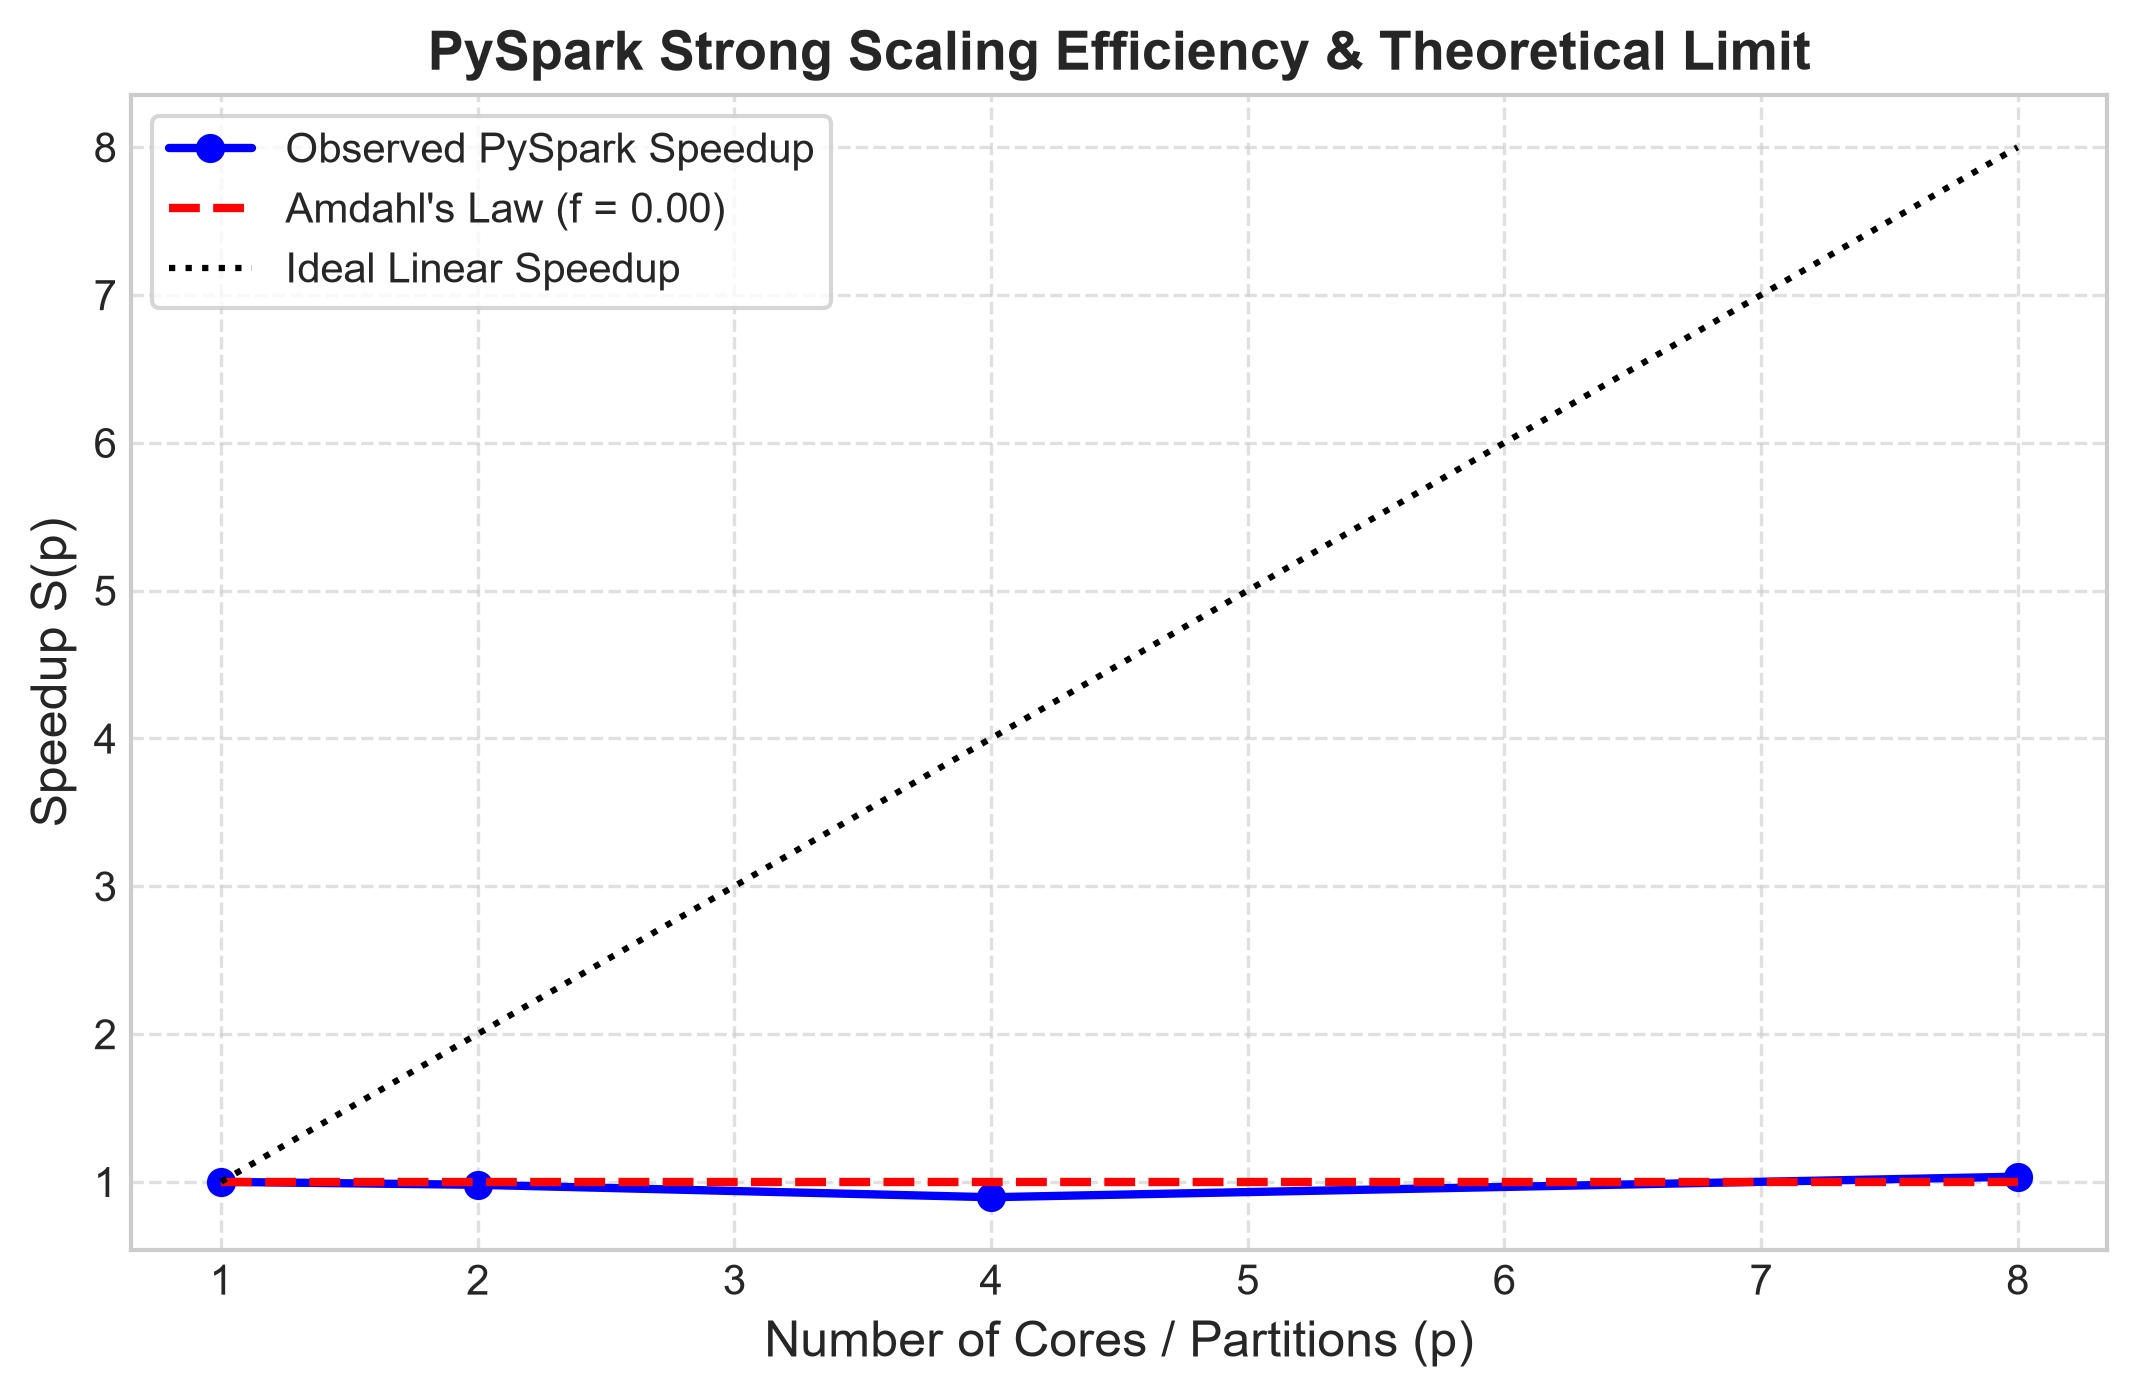

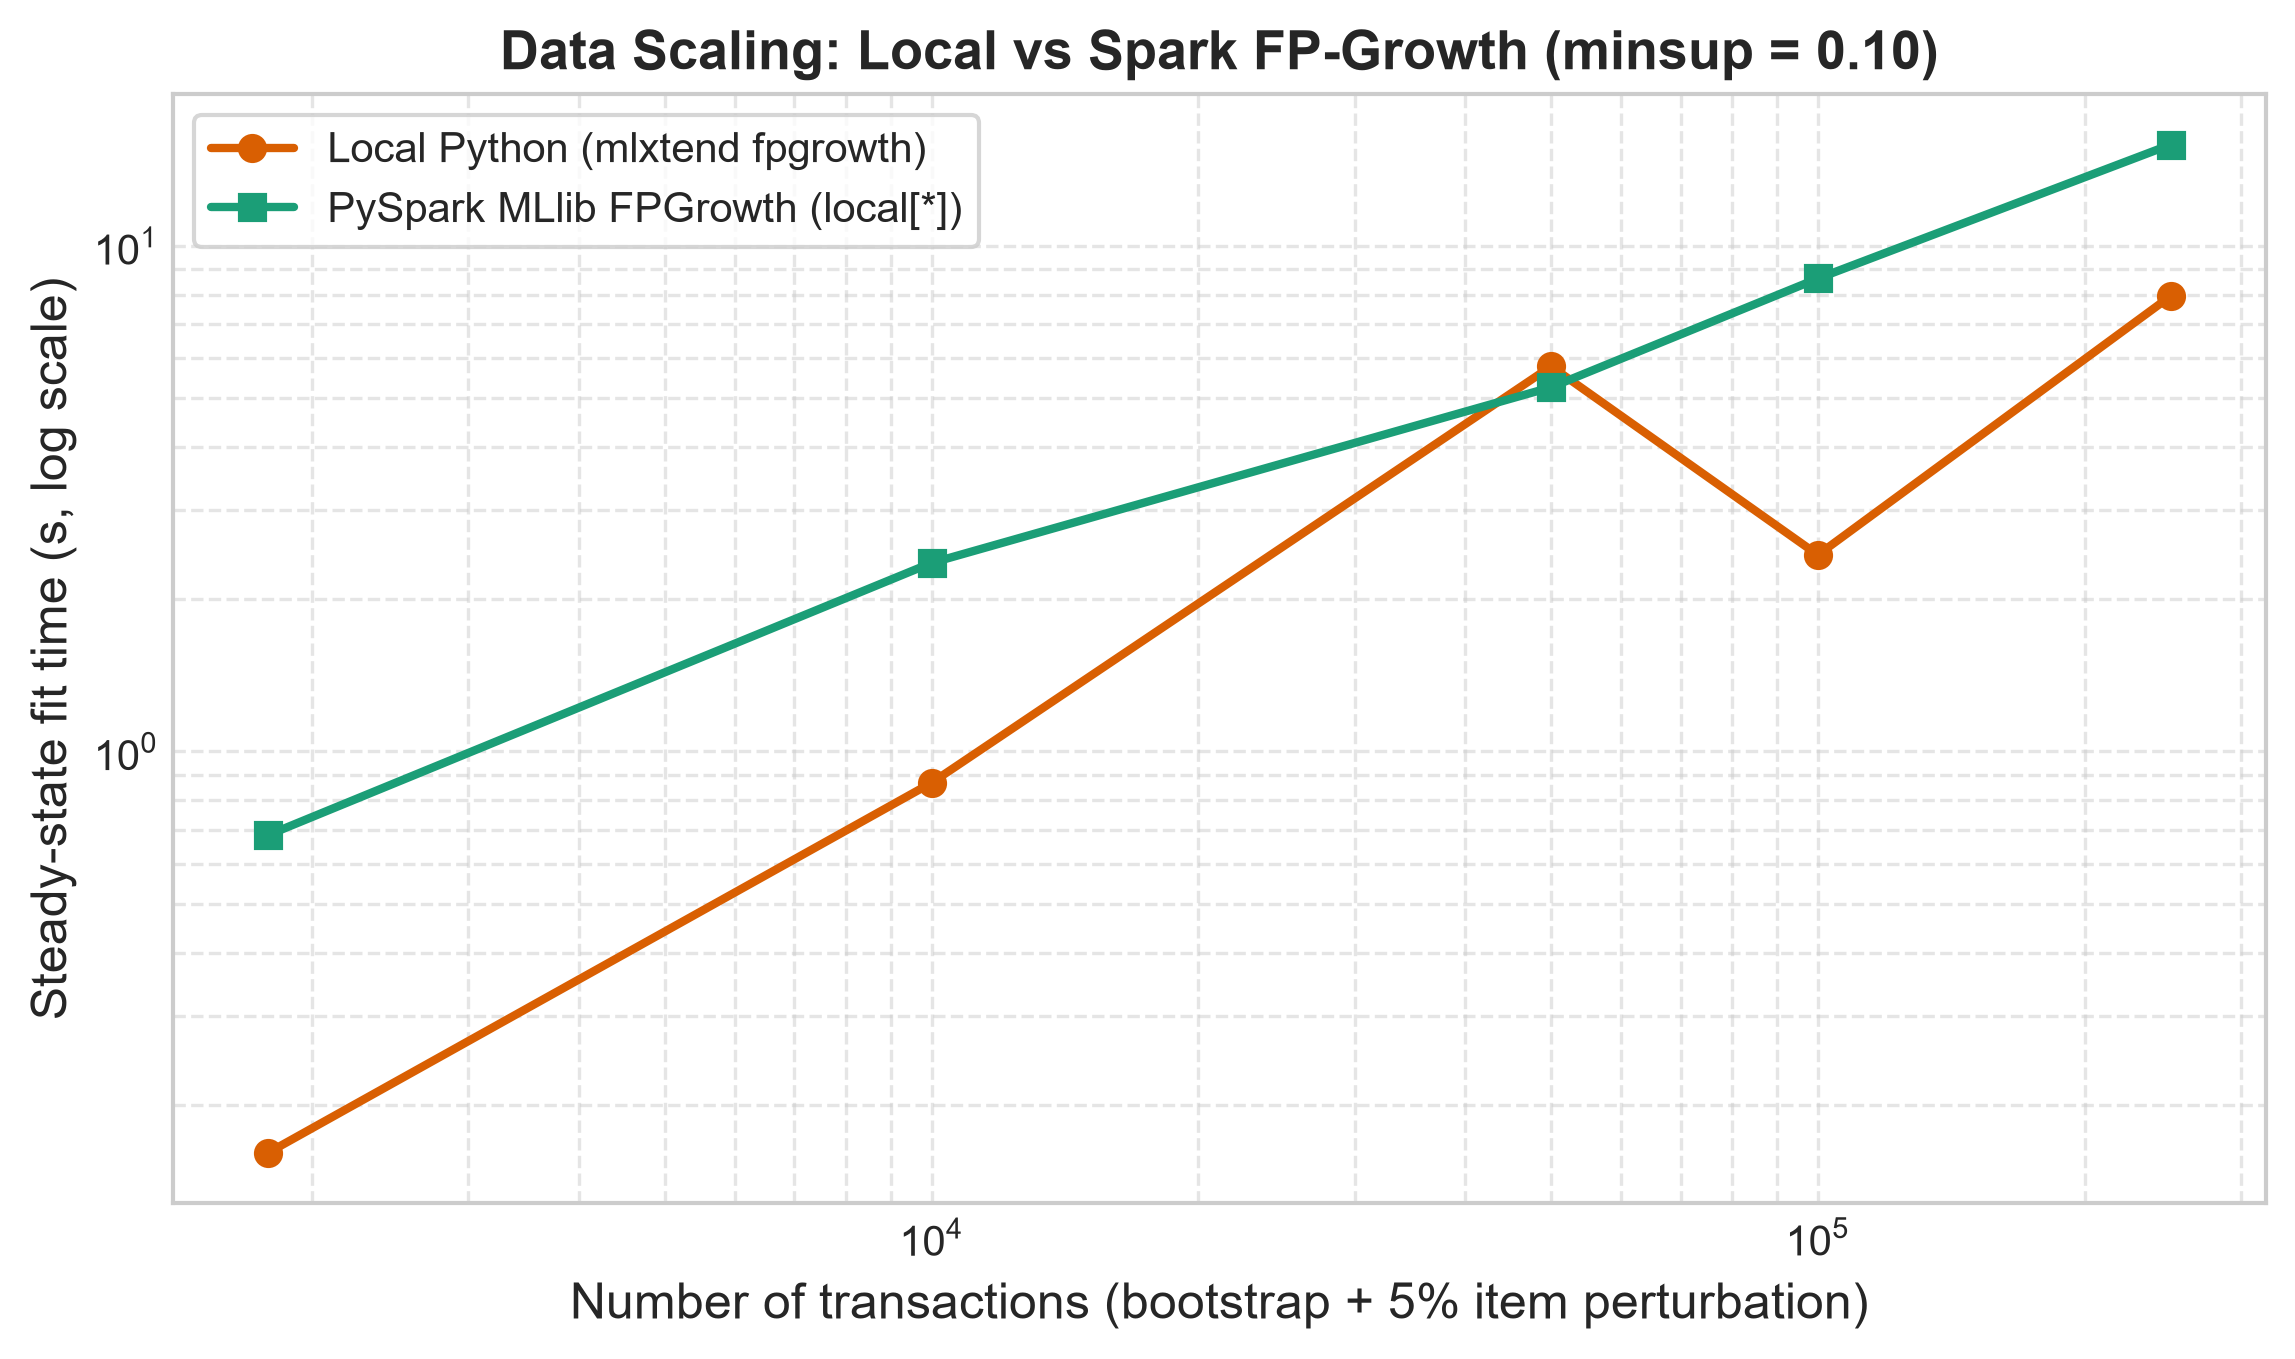

In [2]:
from IPython.display import Image, display
display(Image(filename=str(FIGURES_DIR / 'fig_12_pyspark_strong_scaling_speedup.png')))
display(Image(filename=str(FIGURES_DIR / 'fig_14_local_vs_spark_data_scaling.png')))

## 3. Synthetic Scaling Across Increasing Dataset Sizes
Latency and Peak Physical RSS (psutil) for local mlxtend vs Spark FPGrowth, N = 1,784 to 250,000 rows.

In [3]:
pd.DataFrame(bench['synthetic_scaling']['synthetic_scaling'])

,N_Rows,Distinct_Transactions,Local_Prep_Sec,Local_mlxtend_Sec,Local_Peak_RSS_MB,Local_Itemsets,Spark_Prep_Sec,Spark_FPGrowth_Sec,Spark_Peak_RSS_MB_ProcessTree,Spark_Itemsets,Speedup_Local_over_Spark
0,1784,1688,0.0126,0.1608,1885.76,1017,17.8281,0.6834,1632.45,1017,0.235
1,10000,8008,0.0239,0.8671,1042.85,1027,17.4706,2.3601,1176.89,1027,0.367
2,50000,31098,0.1515,5.7764,1265.42,1027,18.3725,5.2523,2148.98,1027,1.100
3,100000,53585,0.1032,2.4472,1808.34,1026,16.6383,8.6198,2796.83,1026,0.284
4,250000,104163,0.4269,7.9539,1950.98,1022,17.8325,15.8564,3468.05,1022,0.502
